# 04. Bayesian Smoothing & Uncertainty

This notebook applies past-only Bayesian-style smoothing to the Product × Aspect × Quarter series.

Conceptually:

SmoothedScore = [n(CurrentScore) + k(HistoricalMean)] / (n + k)

- `n` = current-quarter review support
- `k` = prior strength
- `HistoricalMean` = mean sentiment from earlier quarters only

`k = 5` is used here only as a development value and must later be tuned using EDA/validation.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    COMPONENT_ROOT = WORKSPACE.parent
elif (WORKSPACE / "data" / "processed").exists():
    COMPONENT_ROOT = WORKSPACE
else:
    COMPONENT_ROOT = WORKSPACE / "component_3"

PAQ_INPUT = COMPONENT_ROOT / "data" / "processed" / "paq_series.csv"
RAW_INPUT = COMPONENT_ROOT / "data" / "processed" / "dummy_c1_output.csv"

OUTPUT_DIR = COMPONENT_ROOT / "data" / "processed"
FIGURE_DIR = COMPONENT_ROOT / "outputs" / "figures"
TABLE_DIR = COMPONENT_ROOT / "outputs" / "tables"

for p in [OUTPUT_DIR, FIGURE_DIR, TABLE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

OUTPUT = OUTPUT_DIR / "paq_smoothed.csv"

DEV_K = 5
BOOTSTRAP_ITERATIONS = 500
RANDOM_SEED = 42


## 1. Load PAQ and raw development data


In [8]:
paq = pd.read_csv(PAQ_INPUT)
raw = pd.read_csv(RAW_INPUT)

raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True, errors="coerce")
raw = raw.dropna(subset=["timestamp"]).copy()

raw["quarter"] = (
    raw["timestamp"]
    .dt.tz_localize(None)
    .dt.to_period("Q")
    .astype(str)
)

raw["aspect"] = raw["aspect"].astype(str).str.lower().str.strip()
raw["sentiment_score"] = pd.to_numeric(raw["sentiment_score"], errors="coerce")

print("PAQ rows:", len(paq))
print("Raw rows:", len(raw))
display(paq.head())


PAQ rows: 550
Raw rows: 4978


,parent_asin,aspect,quarter,review_count,mean_sentiment,median_sentiment,positive_rate,neutral_rate,negative_rate,avg_confidence,first_timestamp,last_timestamp,confidence_weighted_sentiment
0,B00FFJ0HUE,battery,2021Q1,3,0.1326,-0.1452,0.3333,0.6667,0.0,0.7348,2021-01-09 05:39:37+00:00,2021-03-02 01:21:27+00:00,0.1754
1,B00FFJ0HUE,battery,2021Q2,3,-0.0371,-0.0177,0.0000,1.0000,0.0,0.7411,2021-04-21 11:19:50+00:00,2021-05-03 13:49:34+00:00,-0.0449
2,B00FFJ0HUE,battery,2021Q3,5,0.4642,0.4297,0.8000,0.2000,0.0,0.7929,2021-07-01 16:16:52+00:00,2021-09-18 16:39:42+00:00,0.4900
3,B00FFJ0HUE,battery,2021Q4,5,0.2114,0.1513,0.4000,0.6000,0.0,0.7260,2021-10-25 21:56:46+00:00,2021-12-31 04:21:48+00:00,0.2208
4,B00FFJ0HUE,battery,2022Q1,2,0.0833,0.0833,0.5000,0.0000,0.5,0.8004,2022-01-07 02:20:07+00:00,2022-01-30 10:17:47+00:00,0.0905


## 2. Sort chronologically


In [9]:
paq["quarter_period"] = pd.PeriodIndex(paq["quarter"], freq="Q")

paq = (
    paq
    .sort_values(["parent_asin", "aspect", "quarter_period"])
    .reset_index(drop=True)
)


## 3. Calculate past-only historical mean


In [10]:
paq["historical_mean"] = (
    paq
    .groupby(["parent_asin", "aspect"])["mean_sentiment"]
    .transform(lambda s: s.expanding().mean().shift(1))
)

# First observed quarter has no past data.
# Neutral prior is used only for development.
paq["historical_mean"] = paq["historical_mean"].fillna(0.0)

display(
    paq[[
        "parent_asin",
        "aspect",
        "quarter",
        "review_count",
        "mean_sentiment",
        "historical_mean"
    ]].head(20)
)


,parent_asin,aspect,quarter,review_count,mean_sentiment,historical_mean
0,B00FFJ0HUE,battery,2021Q1,3,0.1326,0.000000
1,B00FFJ0HUE,battery,2021Q2,3,-0.0371,0.132600
2,B00FFJ0HUE,battery,2021Q3,5,0.4642,0.047750
3,B00FFJ0HUE,battery,2021Q4,5,0.2114,0.186567
4,B00FFJ0HUE,battery,2022Q1,2,0.0833,0.192775
5,B00FFJ0HUE,battery,2022Q2,6,0.3849,0.170880
6,B00FFJ0HUE,battery,2022Q3,6,0.6222,0.206550
7,B00FFJ0HUE,battery,2022Q4,2,0.3040,0.265929
8,B00FFJ0HUE,battery,2023Q1,2,0.4198,0.270688
9,B00FFJ0HUE,battery,2023Q2,1,0.3722,0.287256


## 4. Apply Bayesian-style smoothing


In [11]:
paq["smoothed_sentiment"] = (
    (paq["review_count"] * paq["mean_sentiment"])
    + (DEV_K * paq["historical_mean"])
) / (paq["review_count"] + DEV_K)

paq["smoothed_sentiment"] = paq["smoothed_sentiment"].clip(-1, 1)

paq["smoothing_adjustment"] = (
    paq["smoothed_sentiment"] - paq["mean_sentiment"]
)

display(
    paq[[
        "parent_asin",
        "aspect",
        "quarter",
        "review_count",
        "mean_sentiment",
        "historical_mean",
        "smoothed_sentiment",
        "smoothing_adjustment"
    ]].head(20)
)


,parent_asin,aspect,quarter,review_count,mean_sentiment,historical_mean,smoothed_sentiment,smoothing_adjustment
0,B00FFJ0HUE,battery,2021Q1,3,0.1326,0.000000,0.049725,-0.082875
1,B00FFJ0HUE,battery,2021Q2,3,-0.0371,0.132600,0.068963,0.106063
2,B00FFJ0HUE,battery,2021Q3,5,0.4642,0.047750,0.255975,-0.208225
3,B00FFJ0HUE,battery,2021Q4,5,0.2114,0.186567,0.198983,-0.012417
4,B00FFJ0HUE,battery,2022Q1,2,0.0833,0.192775,0.161496,0.078196
5,B00FFJ0HUE,battery,2022Q2,6,0.3849,0.170880,0.287618,-0.097282
6,B00FFJ0HUE,battery,2022Q3,6,0.6222,0.206550,0.433268,-0.188932
7,B00FFJ0HUE,battery,2022Q4,2,0.3040,0.265929,0.276806,-0.027194
8,B00FFJ0HUE,battery,2023Q1,2,0.4198,0.270688,0.313291,-0.106509
9,B00FFJ0HUE,battery,2023Q2,1,0.3722,0.287256,0.301413,-0.070787


## 5. Bootstrap uncertainty interval

For each Product × Aspect × Quarter group:
1. resample the current-quarter sentiment values;
2. compute a bootstrap mean;
3. smooth it using the same past-only historical mean;
4. repeat;
5. take the 2.5th and 97.5th percentiles.

This gives a development 95% uncertainty interval.


In [12]:
rng = np.random.default_rng(RANDOM_SEED)

def bootstrap_smoothed_interval(values, historical_mean, k, iterations=500):
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]

    if len(values) == 0:
        return np.nan, np.nan

    n = len(values)
    estimates = []

    for _ in range(iterations):
        sample = rng.choice(values, size=n, replace=True)
        current_mean = sample.mean()

        smoothed = (
            n * current_mean
            + k * historical_mean
        ) / (n + k)

        estimates.append(smoothed)

    return (
        np.percentile(estimates, 2.5),
        np.percentile(estimates, 97.5)
    )

interval_rows = []

for _, row in paq.iterrows():
    subset = raw[
        (raw["parent_asin"] == row["parent_asin"])
        & (raw["aspect"] == row["aspect"])
        & (raw["quarter"] == row["quarter"])
    ]["sentiment_score"].dropna()

    low, high = bootstrap_smoothed_interval(
        subset.values,
        row["historical_mean"],
        DEV_K,
        BOOTSTRAP_ITERATIONS
    )

    interval_rows.append((low, high))

paq["ci_lower"] = [x[0] for x in interval_rows]
paq["ci_upper"] = [x[1] for x in interval_rows]
paq["ci_width"] = paq["ci_upper"] - paq["ci_lower"]

display(
    paq[[
        "parent_asin",
        "aspect",
        "quarter",
        "review_count",
        "smoothed_sentiment",
        "ci_lower",
        "ci_upper",
        "ci_width"
    ]].head(20)
)


,parent_asin,aspect,quarter,review_count,smoothed_sentiment,ci_lower,ci_upper,ci_width
0,B00FFJ0HUE,battery,2021Q1,3,0.049725,-0.067575,0.271162,0.338737
1,B00FFJ0HUE,battery,2021Q2,3,0.068963,0.009600,0.113955,0.104355
2,B00FFJ0HUE,battery,2021Q3,5,0.255975,0.139425,0.363625,0.224200
3,B00FFJ0HUE,battery,2021Q4,5,0.198983,0.136293,0.286623,0.150330
4,B00FFJ0HUE,battery,2022Q1,2,0.161496,0.015754,0.307239,0.291486
5,B00FFJ0HUE,battery,2022Q2,6,0.287618,0.134042,0.446056,0.312014
6,B00FFJ0HUE,battery,2022Q3,6,0.433268,0.265681,0.575432,0.309751
7,B00FFJ0HUE,battery,2022Q4,2,0.276806,0.268320,0.285292,0.016971
8,B00FFJ0HUE,battery,2023Q1,2,0.313291,0.303120,0.323463,0.020343
9,B00FFJ0HUE,battery,2023Q2,1,0.301413,0.301413,0.301413,0.000000


## 6. Development confidence indicator

This is not the final research confidence formula.

For PP1 development:
- more review support helps confidence;
- higher C1 confidence helps confidence;
- narrower bootstrap intervals help confidence.


In [13]:
support_factor = (
    paq["review_count"]
    / (paq["review_count"] + DEV_K)
)

interval_factor = (
    1 - (paq["ci_width"] / 2)
).clip(0, 1)

paq["temporal_confidence_dev"] = (
    0.4 * support_factor
    + 0.3 * paq["avg_confidence"]
    + 0.3 * interval_factor
).clip(0, 1)

def confidence_label(x):
    if x >= 0.80:
        return "High"
    elif x >= 0.60:
        return "Medium"
    return "Low"

paq["confidence_label_dev"] = (
    paq["temporal_confidence_dev"]
    .apply(confidence_label)
)

display(
    paq[[
        "parent_asin",
        "aspect",
        "quarter",
        "review_count",
        "avg_confidence",
        "ci_width",
        "temporal_confidence_dev",
        "confidence_label_dev"
    ]].head(20)
)


,parent_asin,aspect,quarter,review_count,avg_confidence,ci_width,temporal_confidence_dev,confidence_label_dev
0,B00FFJ0HUE,battery,2021Q1,3,0.7348,0.338737,0.619629,Medium
1,B00FFJ0HUE,battery,2021Q2,3,0.7411,0.104355,0.656677,Medium
2,B00FFJ0HUE,battery,2021Q3,5,0.7929,0.224200,0.704240,Medium
3,B00FFJ0HUE,battery,2021Q4,5,0.7260,0.150330,0.695250,Medium
4,B00FFJ0HUE,battery,2022Q1,2,0.8004,0.291486,0.610683,Medium
5,B00FFJ0HUE,battery,2022Q2,6,0.7768,0.312014,0.704420,Medium
6,B00FFJ0HUE,battery,2022Q3,6,0.8082,0.309751,0.714179,Medium
7,B00FFJ0HUE,battery,2022Q4,2,0.7103,0.016971,0.624830,Medium
8,B00FFJ0HUE,battery,2023Q1,2,0.7904,0.020343,0.648354,Medium
9,B00FFJ0HUE,battery,2023Q2,1,0.7591,0.000000,0.594397,Low


## 7. Compare raw vs smoothed values


In [14]:
comparison = paq[[
    "parent_asin",
    "aspect",
    "quarter",
    "review_count",
    "mean_sentiment",
    "historical_mean",
    "smoothed_sentiment",
    "ci_lower",
    "ci_upper",
    "temporal_confidence_dev",
    "confidence_label_dev"
]].copy()

comparison.to_csv(
    TABLE_DIR / "smoothing_comparison.csv",
    index=False
)

display(
    comparison
    .sort_values("review_count")
    .head(20)
)


,parent_asin,aspect,quarter,review_count,mean_sentiment,historical_mean,smoothed_sentiment,ci_lower,ci_upper,temporal_confidence_dev,confidence_label_dev
59,B00KB7O49K,battery,2022Q1,1,0.2941,0.438475,0.414413,0.414413,0.414413,0.599857,Low
75,B00KB7O49K,camera,2023Q2,1,0.5037,0.557533,0.548561,0.548561,0.548561,0.601267,Medium
73,B00KB7O49K,camera,2022Q4,1,1.0000,0.470514,0.558762,0.558762,0.558762,0.629317,Medium
64,B00KB7O49K,battery,2023Q2,1,0.1567,0.466011,0.414459,0.414459,0.414459,0.568387,Low
97,B00KB7O49K,performance,2023Q2,1,0.1529,0.414100,0.370567,0.370567,0.370567,0.567607,Low
106,B00KB7O49K,thermal,2022Q4,1,0.4426,0.353086,0.368005,0.368005,0.368005,0.604117,Medium
84,B00KB7O49K,display,2022Q4,1,0.6614,0.268414,0.333912,0.333912,0.333912,0.617617,Medium
9,B00FFJ0HUE,battery,2023Q2,1,0.3722,0.287256,0.301413,0.301413,0.301413,0.594397,Low
15,B00FFJ0HUE,display,2022Q1,1,-0.0952,0.301475,0.235363,0.235363,0.235363,0.574147,Low
12,B00FFJ0HUE,display,2021Q2,1,-0.2367,0.312300,0.220800,0.220800,0.220800,0.572527,Low


## 8. Plot one low-support example


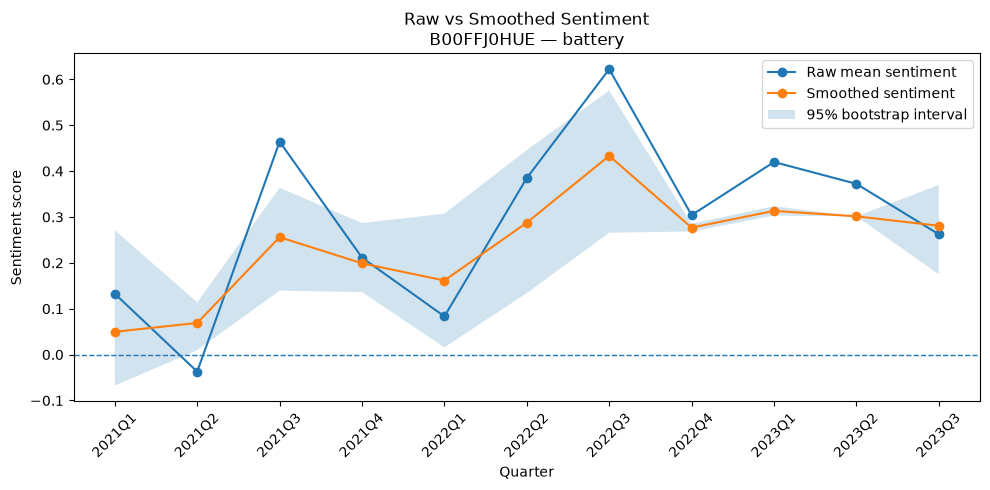

In [15]:
candidate = (
    paq
    .sort_values(["review_count", "ci_width"], ascending=[True, False])
    .iloc[0]
)

example_product = candidate["parent_asin"]
example_aspect = candidate["aspect"]

example = paq[
    (paq["parent_asin"] == example_product)
    & (paq["aspect"] == example_aspect)
].copy()

example = example.sort_values("quarter_period")

plt.figure(figsize=(10, 5))

plt.plot(
    example["quarter"],
    example["mean_sentiment"],
    marker="o",
    label="Raw mean sentiment"
)

plt.plot(
    example["quarter"],
    example["smoothed_sentiment"],
    marker="o",
    label="Smoothed sentiment"
)

plt.fill_between(
    example["quarter"],
    example["ci_lower"],
    example["ci_upper"],
    alpha=0.2,
    label="95% bootstrap interval"
)

plt.axhline(0, linewidth=1, linestyle="--")

plt.title(
    f"Raw vs Smoothed Sentiment\n"
    f"{example_product} — {example_aspect}"
)

plt.xlabel("Quarter")
plt.ylabel("Sentiment score")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "raw_vs_smoothed_example.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 9. Save the smoothed PAQ table


In [16]:
paq = paq.drop(columns=["quarter_period"])

numeric_cols = [
    "historical_mean",
    "smoothed_sentiment",
    "smoothing_adjustment",
    "ci_lower",
    "ci_upper",
    "ci_width",
    "temporal_confidence_dev"
]

for c in numeric_cols:
    paq[c] = paq[c].round(4)

paq.to_csv(OUTPUT, index=False)

print("Saved:", OUTPUT)
print("Rows:", len(paq))


Saved: c:\Users\victus\Desktop\Repository\J26-DS-349\component_3\data\processed\paq_smoothed.csv
Rows: 550
